# AA3 · Parcial II · Cuaderno 2: Embeddings

**Alumno:** Edgar Mauricio Trejo Delgado

**Datos:** Reseñas de productos de Amazon en español, clasificadas de 1 a 5 estrellas · [SetFit/amazon_reviews_multi_es](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es) (versión en el Hub del corpus *Multilingual Amazon Reviews*, Keung et al., 2020)

## 1. Datos
Parte 1 del ejercicio final de la Práctica 4: **conjunto contra secuencia en español**.

- **Fuente:** [huggingface.co/datasets/SetFit/amazon_reviews_multi_es](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es).
- **Tarea:** a partir del texto de la reseña, predecir sus estrellas: **5 clases** (1★ a 5★), balanceadas.
- **División:** el `train` del Hub se divide 80/20 en entrenamiento y validación **con semilla**; el `test` del Hub es la prueba y se usa **una sola vez** por modelo.

En Colab el motor de Keras es **TensorFlow**, como en la práctica (con PyTorch la Bi-LSTM pierde cuDNN).

In [1]:
import os
import sys
import time
import importlib.util

EN_COLAB = importlib.util.find_spec("google.colab") is not None
os.environ["KERAS_BACKEND"] = "tensorflow" if EN_COLAB else "torch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

if importlib.util.find_spec("datasets") is None:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])

import keras
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)
DIR_MODELOS = os.path.join("modelos", "C2")
os.makedirs(DIR_MODELOS, exist_ok=True)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", 200)

print(f"Entorno: {'Google Colab' if EN_COLAB else 'Local'} · Keras {keras.__version__} · backend: {keras.backend.backend()}")
print(f"TensorFlow {tf.__version__} · GPU: {tf.config.list_physical_devices('GPU')}")

Entorno: Google Colab · Keras 3.13.2 · backend: tensorflow
TensorFlow 2.21.0 · GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
URL_DATASET = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es"

def cargar(parte):
    try:
        from datasets import load_dataset
        return load_dataset("SetFit/amazon_reviews_multi_es", split=parte).to_pandas()
    except Exception as error:
        print(f"load_dataset falló ({error}); se lee el archivo JSON directo del Hub.")
        return pd.read_json(f"{URL_DATASET}/resolve/main/{parte}.jsonl", lines=True)

df_hub_train = cargar("train").dropna(subset=["text", "label"])
df_hub_test = cargar("test").dropna(subset=["text", "label"])
df_hub_train["label"] = df_hub_train["label"].astype(int)
df_hub_test["label"] = df_hub_test["label"].astype(int)

CLASES = sorted(df_hub_train["label"].unique())
NOMBRES = [f"{c + 1}★" for c in CLASES]   # label 0 = 1 estrella … label 4 = 5 estrellas
n_clases = len(CLASES)

# División con semilla: entrenamiento / validación (80 / 20), estratificada
df_train, df_val = train_test_split(df_hub_train, test_size=0.2, stratify=df_hub_train["label"], random_state=SEED)
x_train, y_train = df_train["text"].tolist(), df_train["label"].to_numpy("int32")
x_val, y_val = df_val["text"].tolist(), df_val["label"].to_numpy("int32")
x_test, y_test = df_hub_test["text"].tolist(), df_hub_test["label"].to_numpy("int32")

print(f"Columnas: {list(df_hub_train.columns)}")
print(f"Ejemplos en total: {len(df_hub_train) + len(df_hub_test):,} · clases: {n_clases} ({', '.join(NOMBRES)})")
print(f"Entrenamiento: {len(x_train):,} · Validación: {len(x_val):,} · Prueba: {len(x_test):,}")
pd.DataFrame({"entrenamiento": pd.Series(y_train).value_counts().sort_index(),
              "validación": pd.Series(y_val).value_counts().sort_index(),
              "prueba": pd.Series(y_test).value_counts().sort_index()}).set_axis(NOMBRES)

README.md:   0%|          | 0.00/310 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B / 43.8MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.09M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

... (2 outputs left out)

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Repo card metadata block was not found. Setting CardData to empty.


Columnas: ['id', 'text', 'label', 'label_text']
Ejemplos en total: 205,000 · clases: 5 (1★, 2★, 3★, 4★, 5★)
Entrenamiento: 160,000 · Validación: 40,000 · Prueba: 5,000


,entrenamiento,validación,prueba
1★,32000,8000,1000
2★,32000,8000,1000
3★,32000,8000,1000
4★,32000,8000,1000
5★,32000,8000,1000


In [3]:
for c in CLASES:
    ejemplo = df_train[df_train["label"] == c]["text"].iloc[0]
    print(f"{NOMBRES[c]}: {ejemplo[:250]}")

1★: Tuve que devolver el producto porque no venía en castellano, cuando en la descripción del mismo indicaba que estaba ese idioma.
2★: Mala calidad del chocolate.. Sabor amargo dura poco. Eso sí tacto es rigidez muy buena
3★: Son muy pequeñas. Me esperaba q fueran de mayor tamaño. Por el precio tampoco se pierde mucho, así q.... L próxima vez pediré un tamaño mayor
4★: Es un producto totalmente nuevo con embalaje.... La Usado unas pocas veces y x ahora todo perfecto.. Muy contento
5★: Perfecto para hacerse fotos en lugares con poca luz, es del tamaño perfecto para los smartphones actuales, no requieren de cable conectado al móvil ya que posee batería que dura bastante. Se acopla al móvil mediante presión ya que es una pinza que ap


### El cociente de Google
$$\text{cociente} = \frac{\text{muestras de entrenamiento}}{\text{mediana de palabras por muestra}}$$
Menor que 1,500 → bigramas (conjunto). 1,500 o más → modelo de secuencia.

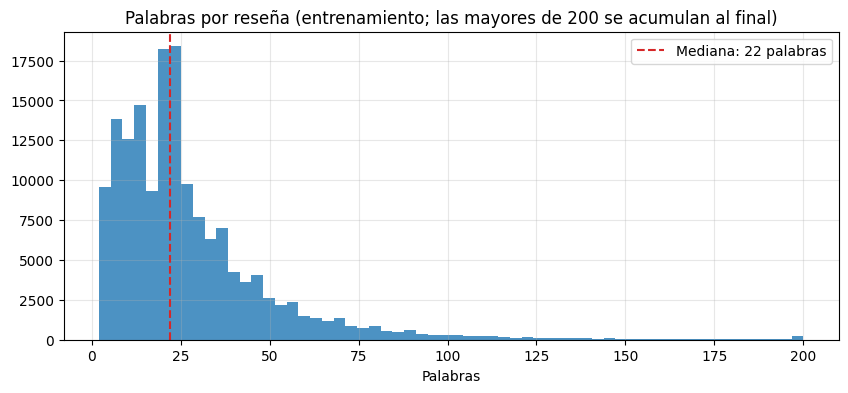

Reseñas de entrenamiento: 160,000 · mediana: 22 palabras · percentil 95: 72
Cociente = 160,000 / 22 = 7,273
Predicción de la regla: MODELO DE SECUENCIA


In [4]:
longitudes = np.array([len(t.split()) for t in x_train])
n_train = len(longitudes)
mediana = np.median(longitudes)
cociente = n_train / mediana

plt.figure(figsize=(10, 4))
plt.hist(np.clip(longitudes, 0, 200), bins=60, color="tab:blue", alpha=0.8)
plt.axvline(mediana, color="tab:red", linestyle="--", label=f"Mediana: {mediana:.0f} palabras")
plt.title("Palabras por reseña (entrenamiento; las mayores de 200 se acumulan al final)")
plt.xlabel("Palabras")
plt.legend()
plt.show()

print(f"Reseñas de entrenamiento: {n_train:,} · mediana: {mediana:.0f} palabras · percentil 95: {np.percentile(longitudes, 95):.0f}")
print(f"Cociente = {n_train:,} / {mediana:.0f} = {cociente:,.0f}")
print("Predicción de la regla:", "BIGRAMAS (modelo de conjunto)" if cociente < 1500 else "MODELO DE SECUENCIA")

> **Mi predicción, escrita antes de entrenar:** el cociente queda muy por encima de 1,500 (muchas reseñas y muy cortas), así que la regla dice que **gana el modelo de secuencia**. Predigo que la **Embedding + Bi-LSTM gana, pero por poco (1 o 2 puntos)**. Las reseñas son cortas y buena parte de la señal está en palabras clave ("excelente", "no funciona", "devolví"), que los bigramas también capturan. Además, distinguir 4★ de 5★ o 2★ de 1★ es difícil para cualquiera de los dos modelos, así que espero exactitudes de alrededor de 50 %, no de 90 % como en IMDb.

In [5]:
# Del texto al tensor: el vocabulario se construye SOLO con el entrenamiento (adapt)
BATCH = 64
LONGITUD = int(min(600, max(50, np.ceil(np.percentile(longitudes, 95) / 10) * 10)))   # cubre el 95 % de las reseñas

def a_dataset(textos, etiquetas, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((np.array(textos, dtype=object), etiquetas))
    if mezclar:
        ds = ds.shuffle(len(textos), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH)

train_ds, val_ds, test_ds = a_dataset(x_train, y_train, mezclar=True), a_dataset(x_val, y_val), a_dataset(x_test, y_test)
textos_train = tf.data.Dataset.from_tensor_slices(np.array(x_train, dtype=object)).batch(1024)

def crear_vectorizador(nombre, **kwargs):
    t0 = time.time()
    v = layers.TextVectorization(**kwargs)   # minúsculas y sin puntuación
    v.adapt(textos_train)
    print(f"{nombre:8s} listo en {time.time() - t0:4.1f} s · vocabulario: {v.vocabulary_size():,}")
    return v

def vectorizar(ds, vectorizador):
    return ds.map(lambda x, y: (vectorizador(x), y), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

vec_bi = crear_vectorizador("vec_bi", max_tokens=30_000, output_mode="multi_hot", ngrams=2)
vec_seq = crear_vectorizador("vec_seq", max_tokens=30_000, output_mode="int", output_sequence_length=LONGITUD)

train_bi, val_bi, test_bi = (vectorizar(d, vec_bi) for d in (train_ds, val_ds, test_ds))
train_seq, val_seq, test_seq = (vectorizar(d, vec_seq) for d in (train_ds, val_ds, test_ds))
print(f"Secuencias de {LONGITUD} tokens (relleno o recorte)")

vec_bi   listo en  6.1 s · vocabulario: 30,000
vec_seq  listo en  2.2 s · vocabulario: 30,000
Secuencias de 80 tokens (relleno o recorte)


## 2. Línea base
El modelo de **bigramas** del Bloque 4: *multi-hot* de 30,000 palabras y pares de palabras → `Dense(16, relu)` → `Dropout(0.5)` → salida. Como hay **5 clases**, la salida es `Dense(5, softmax)` y la pérdida es `sparse_categorical_crossentropy`, en lugar de la sigmoide y la entropía cruzada binaria de IMDb.

Model: "bigramas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ multi_hot (InputLayer)          │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       480,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,101 (1.83 MB)

 Trainable params: 480,101 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
2500/2500 - 33s - 13ms/step - accuracy: 0.4631 - loss: 1.2361 - val_accuracy: 0.5246 - val_loss: 1.1030
Epoch 2/10
2500/2500 - 26s - 10ms/step - accuracy: 0.5040 - loss: 1.1715 - val_accuracy: 0.5249 - val_loss: 1.1091
Epoch 3/10
2500/2500 - 40s - 16ms/step - accuracy: 0.5059 - loss: 1.1680 - val_accuracy: 0.5205 - val_loss: 1.1162
Epoch 4/10
2500/2500 - 25s - 10ms/step - accuracy: 0.5097 - loss: 1.1635 - val_accuracy: 0.5213 - val_loss: 1.1176
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.

Bigramas (multi-hot): exactitud val 0.525 · PRUEBA 0.534


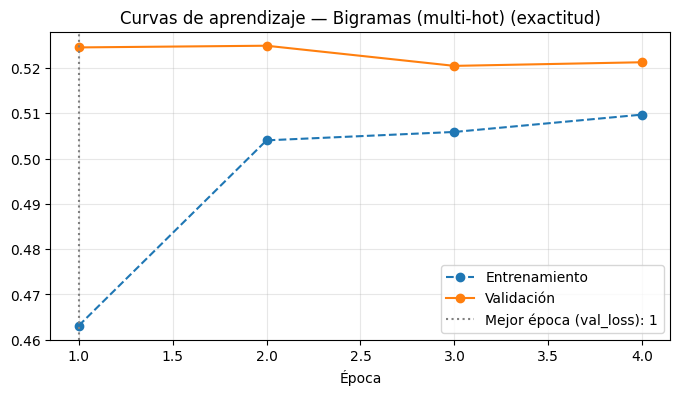

In [6]:
registro = {}

def obtener_callbacks(nombre, paciencia=3):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
            keras.callbacks.ModelCheckpoint(filepath=os.path.join(DIR_MODELOS, f"{nombre}.keras"),
                                            monitor="val_loss", save_best_only=True, verbose=0)]

def graficar_curvas(history, titulo=""):
    entr, val = history.history["accuracy"], history.history["val_accuracy"]
    mejor = int(np.argmin(history.history["val_loss"]))
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(entr) + 1), entr, "o--", label="Entrenamiento")
    plt.plot(range(1, len(val) + 1), val, "o-", label="Validación")
    plt.axvline(mejor + 1, color="gray", linestyle=":", label=f"Mejor época (val_loss): {mejor + 1}")
    plt.title(f"Curvas de aprendizaje — {titulo} (exactitud)")
    plt.xlabel("Época")
    plt.legend()
    plt.show()

def entrenar_texto(nombre, archivo, modelo, ds_train, ds_val, ds_test, familia, epocas=10, paciencia=3):
    # Entrena con parada temprana y evalúa en prueba UNA sola vez
    modelo.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    history = modelo.fit(ds_train, validation_data=ds_val, epochs=epocas,
                         callbacks=obtener_callbacks(archivo, paciencia), verbose=2)
    duracion = time.time() - t0
    _, exactitud_prueba = modelo.evaluate(ds_test, verbose=0)
    mejor = int(np.argmin(history.history["val_loss"]))
    registro[nombre] = {"Familia": familia, "Exactitud val": history.history["val_accuracy"][mejor],
                        "Exactitud prueba": exactitud_prueba, "Parámetros": modelo.count_params(),
                        "Épocas": len(history.history["loss"]), "Seg/época": duracion / len(history.history["loss"])}
    print(f"\n{nombre}: exactitud val {registro[nombre]['Exactitud val']:.3f} · PRUEBA {exactitud_prueba:.3f}")
    graficar_curvas(history, nombre)
    return history

entradas = keras.Input(shape=(vec_bi.vocabulary_size(),), name="multi_hot")
x = layers.Dense(16, activation="relu")(entradas)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(n_clases, activation="softmax")(x)
modelo_bi = keras.Model(entradas, salidas, name="bigramas")
modelo_bi.summary()
hist_bi = entrenar_texto("Bigramas (multi-hot)", "bigramas", modelo_bi, train_bi, val_bi, test_bi, familia="Conjunto")

## 3. Modelo
**Embedding + Bi-LSTM** del Bloque 5, con las **mismas reglas** que los bigramas: la misma división con semilla, el vocabulario construido solo con el entrenamiento, la misma parada temprana y la prueba usada una sola vez.

| Capa | Salida |
|---|---|
| `Embedding(30,000, 64)` | (lote, LONGITUD, 64) |
| `Bidirectional(LSTM(32))` | (lote, 64) |
| `Dropout(0.5)` + `Dense(5, softmax)` | (lote, 5) |

Igual que en la práctica, sin máscara (`mask_zero=False`), para que los resultados sean comparables con los de clase.

Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ indices (InputLayer)            │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_palabras (Embedding)  │ (None, None, 64)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,945,157 (7.42 MB)

 Trainable params: 1,945,157 (7.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
2500/2500 - 38s - 15ms/step - accuracy: 0.4757 - loss: 1.1940 - val_accuracy: 0.5137 - val_loss: 1.1072
Epoch 2/10
2500/2500 - 33s - 13ms/step - accuracy: 0.5274 - loss: 1.0867 - val_accuracy: 0.5260 - val_loss: 1.0748
Epoch 3/10
2500/2500 - 32s - 13ms/step - accuracy: 0.5470 - loss: 1.0474 - val_accuracy: 0.5339 - val_loss: 1.0562
Epoch 4/10
2500/2500 - 33s - 13ms/step - accuracy: 0.5618 - loss: 1.0197 - val_accuracy: 0.5361 - val_loss: 1.0493
Epoch 5/10
2500/2500 - 32s - 13ms/step - accuracy: 0.5738 - loss: 0.9954 - val_accuracy: 0.5364 - val_loss: 1.0499
Epoch 6/10
2500/2500 - 34s - 13ms/step - accuracy: 0.5870 - loss: 0.9732 - val_accuracy: 0.5337 - val_loss: 1.0507
Epoch 7/10
2500/2500 - 34s - 13ms/step - accuracy: 0.6016 - loss: 0.9508 - val_accuracy: 0.5282 - val_loss: 1.0800
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.

Embedding + Bi-LSTM: exactitud val 0.536 · PRUEBA 0.543


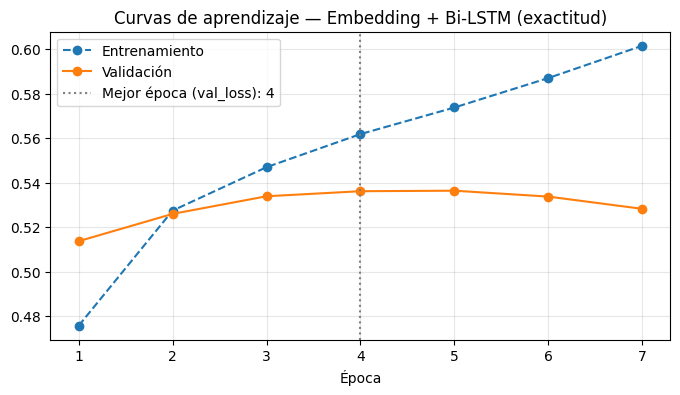

In [7]:
keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(None,), dtype="int64", name="indices")
x = layers.Embedding(vec_seq.vocabulary_size(), 64, mask_zero=False, name="embedding_palabras")(entradas)
x = layers.Bidirectional(layers.LSTM(32))(x)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(n_clases, activation="softmax")(x)
modelo_seq = keras.Model(entradas, salidas, name="bilstm")
modelo_seq.summary()
hist_seq = entrenar_texto("Embedding + Bi-LSTM", "bilstm", modelo_seq, train_seq, val_seq, test_seq, familia="Secuencia")

## 4. Resultados

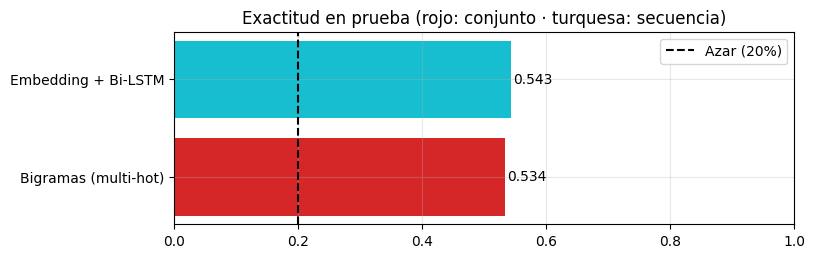

In [8]:
tabla = pd.DataFrame(registro).T
plt.figure(figsize=(8, 2.5))
plt.barh(tabla.index, tabla["Exactitud prueba"].astype(float),
         color=["tab:red" if f == "Conjunto" else "tab:cyan" for f in tabla["Familia"]])
for i, v in enumerate(tabla["Exactitud prueba"].astype(float)):
    plt.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.axvline(1 / n_clases, color="black", linestyle="--", label=f"Azar ({1 / n_clases:.0%})")
plt.xlim(0, 1)
plt.title("Exactitud en prueba (rojo: conjunto · turquesa: secuencia)")
plt.legend()
plt.show()

In [9]:
resultados = pd.DataFrame(registro).T
for c in ["Exactitud val", "Exactitud prueba", "Seg/época"]:
    resultados[c] = resultados[c].astype(float).round(3)
resultados["Parámetros"] = resultados["Parámetros"].astype(int)
resultados = resultados.sort_values("Exactitud prueba", ascending=False)
resultados

,Familia,Exactitud val,Exactitud prueba,Parámetros,Épocas,Seg/época
Embedding + Bi-LSTM,Secuencia,0.536,0.543,1945157,7,33.599
Bigramas (multi-hot),Conjunto,0.525,0.534,480101,4,31.197


## 5. Conclusión

In [10]:
ganador = resultados.index[0]
familia_ganadora = resultados["Familia"].iloc[0]
diferencia = (resultados["Exactitud prueba"].iloc[0] - resultados["Exactitud prueba"].iloc[1]) * 100
prediccion_regla = "Conjunto" if cociente < 1500 else "Secuencia"
print(f"Cociente: {cociente:,.0f} → la regla predice: {'bigramas' if prediccion_regla == 'Conjunto' else 'modelo de secuencia'}")
print(f"Ganador en prueba: {ganador} ({familia_ganadora}) por {diferencia:.1f} puntos")
print(f"¿Se cumplió la regla del cociente?: {'SÍ' if familia_ganadora == prediccion_regla else 'NO'}")

Cociente: 7,273 → la regla predice: modelo de secuencia
Ganador en prueba: Embedding + Bi-LSTM (Secuencia) por 0.9 puntos
¿Se cumplió la regla del cociente?: SÍ


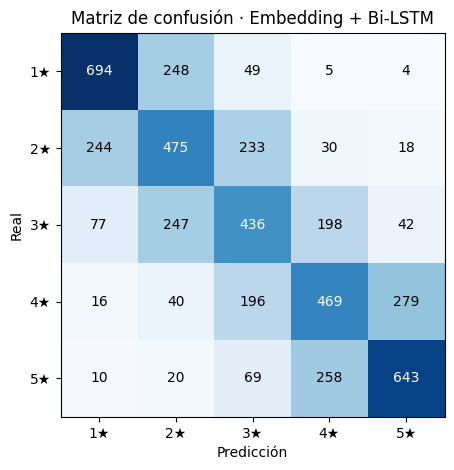

Errores: 2,283 de 5,000 (45.7%)
  a 1 estrella de distancia:  83.4% de los errores
  a 2 o más estrellas:        16.6% de los errores
Exactitud por clase: {'1★': '69%', '2★': '48%', '3★': '44%', '4★': '47%', '5★': '64%'}


In [11]:
# Errores del mejor modelo en la prueba
modelos = {"Bigramas (multi-hot)": (modelo_bi, test_bi), "Embedding + Bi-LSTM": (modelo_seq, test_seq)}
modelo_mejor, ds_mejor = modelos[ganador]
probs = modelo_mejor.predict(ds_mejor, verbose=0)
pred = probs.argmax(axis=1)

from sklearn.metrics import confusion_matrix
M = confusion_matrix(y_test, pred, labels=CLASES)
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ax.imshow(M, cmap="Blues")
ax.set_xticks(range(n_clases), NOMBRES)
ax.set_yticks(range(n_clases), NOMBRES)
for i in range(n_clases):
    for j in range(n_clases):
        ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión · {ganador}")
ax.grid(False)
plt.tight_layout()
plt.show()

errores = pred != y_test
distancia = np.abs(pred - y_test)[errores]
print(f"Errores: {errores.sum():,} de {len(y_test):,} ({errores.mean():.1%})")
print(f"  a 1 estrella de distancia:  {np.mean(distancia == 1):.1%} de los errores")
print(f"  a 2 o más estrellas:        {np.mean(distancia >= 2):.1%} de los errores")
print("Exactitud por clase:", {NOMBRES[c]: f"{M[c, c] / M[c].sum():.0%}" for c in CLASES})

In [12]:
# Los 10 errores en los que el modelo estaba MÁS seguro
idx_err = np.where(errores)[0]
idx_err = idx_err[np.argsort(-probs[idx_err].max(axis=1))][:10]
ejemplos_error = pd.DataFrame({
    "Reseña": [x_test[i][:220] for i in idx_err],
    "Real": [NOMBRES[y_test[i]] for i in idx_err],
    "Predicción": [NOMBRES[pred[i]] for i in idx_err],
    "Prob.": [f"{probs[i].max():.2f}" for i in idx_err],
})
ejemplos_error

,Reseña,Real,Predicción,Prob.
0,Nunca llego el pedido contacte con el comprador y dijo que la empresa de transportes lo perdio. Por suerte me reembolso el dinero sin más. En este aspecto de comunicación con el vendedor estoy con...,2★,1★,0.98
1,"No puedo valorar el producto, nunca llego a destino",2★,1★,0.96
2,"Pues no puedo valorarlo todavía, aún no lo he recibido. Ya vamos con tres días de retraso. Esperaré a ver que pasa.",2★,1★,0.96
3,"Se ha estropeado, no funciona en ningún ordenador ni con el movil y ni siquiera sé por qué. No lo recomiendo",2★,1★,0.95
4,"Mala calidad, solo han funcionado correctamente un mes. Se han estropeado y no funcionan.",2★,1★,0.94
5,"Es de malisima calidad, la talla no coincide, es demaciado pequeño y feo. Una decepsion total. No lo recmiendo comprar, no es mucho dinero, pero es tirar dinero a la basura. Y tarda mas de un mes ...",2★,1★,0.94
6,"Compré dos mochilas, una roja y otra azul y la roja venía sin correa. Le escribí al vendedor y 5 días después sigo sin tener respuesta alguna por su parte. Muy decepcionada.",2★,1★,0.94
7,"No ha llegado ,aún .pero hace 20 días pedí otro y llegó sin ser el de mi modelo,valore' mal por ello este envío y prometieron devolverme el dinero y aún no lo he recibido",2★,1★,0.94
8,"Mala calidad, solo funciona la mitad, nada recomendable",3★,1★,0.94
9,Muy mala calidad. El táctil no funcionaba bien y cada dos por tres se reiniciará sola. Mala.,2★,1★,0.94


**¿Se cumplió la regla del cociente?** **Sí, pero por muy poco.** El cociente queda muy por encima de 1,500 (muchas reseñas y muy cortas), así que la regla predecía que ganaría el modelo de secuencia, y así fue: la **Embedding + Bi-LSTM** alcanzó **54.3 %** de exactitud en prueba contra **53.4 %** de los bigramas, una diferencia de solo **0.9 puntos** (en validación, 53.6 % contra 52.5 %). Se cumplió también mi predicción escrita antes de entrenar: gana la secuencia, por poco, y alrededor de 50 %.

Pero la ventaja es pequeña para lo que cuesta: la Bi-LSTM tiene **4 veces más parámetros** (1,945,157 contra 480,101) y tardó más épocas en converger (7 contra 4). Con reseñas tan cortas casi no hay orden de largo alcance que aprovechar, y los bigramas ya capturan lo esencial ("no funciona", "mala calidad", "muy recomendable"). Las dos quedan muy por encima del azar (20 %).

**¿Qué errores comete el mejor modelo?** La Bi-LSTM se equivoca en 2,283 de 5,000 reseñas de prueba (45.7 %), pero sus errores tienen un patrón claro:

1. **Casi todos son entre estrellas vecinas.** El **83.4 %** de los errores está a una sola estrella de distancia; solo el 16.6 % se va a dos o más. La matriz de confusión muestra los bloques: 1★ ↔ 2★ (248 y 244 confusiones) y 4★ ↔ 5★ (279 y 258). El modelo sí distingue lo positivo de lo negativo; lo que no logra es la intensidad, que es subjetiva: dos personas escriben casi lo mismo y una pone 1★ y otra 2★.
2. **Los extremos son fáciles y el centro es difícil.** Exactitud por clase: 1★ 69 % y 5★ 64 %, contra 2★ 48 %, 4★ 47 % y **3★ 44 %**, la peor. Las reseñas de 3★ son mixtas ("está bien pero…") y el modelo las reparte hacia 2★ (247) y 4★ (198).
3. **Califican el envío, no el producto.** Varios de los errores más seguros son reseñas de 2★ que el modelo marcó como 1★ con 94-98 % de seguridad, y en las que el producto ni siquiera llegó: «No puedo valorar el producto, nunca llegó a destino», «Pues no puedo valorarlo todavía, aún no lo he recibido», «Nunca llegó el pedido… la empresa de transportes lo perdió». El texto es negativo, pero la persona puso 2★ en lugar de 1★. El modelo no puede saber esa decisión.
4. **Texto muy negativo con calificación media (etiquetas ruidosas).** «Es de malísima calidad… Una decepción total. No lo recomiendo comprar… es tirar dinero a la basura» tiene **2★**, y «Mala calidad, solo funciona la mitad, nada recomendable» tiene **3★**. Cualquier lector diría 1★: aquí no se equivoca el modelo, sino que la etiqueta no concuerda con el texto. Los diez errores más seguros son todos del mismo tipo: reseñas claramente negativas con 2★ o 3★, predichas como 1★.

En resumen, buena parte del 45.7 % de error no se puede eliminar con un mejor modelo: viene de la propia tarea, porque las estrellas dependen de la escala personal de cada quien y no solo de lo que dice el texto.